# Baseline Model Evaluation and Comparison

## Objective

The goal of this notebook is to establish a simple baseline
for the Atomity Cloud Workload Forecasting challenge.

We use a Persistence Baseline, which predicts future values
using the last observed values.

We evaluate the baseline using time-aware validation and
compare it with a Gradient Boosting model.

The evaluation includes:
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- Actual vs. predicted plots
- Relative improvement over the baseline

Both models forecast two targets:
1. active_vm_count
2. aggregate_cpu_utilization

The final 24 observations remain held out until the final
evaluation.

In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from pathlib import Path

In [ ]:
import sys
from pathlib import Path
import importlib
import src.prepocessing as prep
project_path = Path.cwd().parent
sys.path.insert(0, str(project_path))

from src.prepocessing import preproce
importlib.reload(prep)

print(project_path)
print((project_path / "src").exists())

f:\forecasting-challenge
True


In [89]:
x_train, y_train, y_test, timestamps_test, history = preproce()

print("Training features:", x_train.shape)
print("Training targets:", y_train.shape)
print("Test targets:", y_test.shape)
print("Test timestamps:", len(timestamps_test))
print("Historical data:", history.shape)

Training features: (107, 6)
Training targets: (107, 2)
Test targets: (24, 2)
Test timestamps: 24
Historical data: (110, 2)


## 1. Persistence Baseline

The Persistence Baseline assumes that the next observation
will be equal to the most recent observed value.

For example, if the last observed active VM count is 10,000,
the baseline predicts 10,000 for every future timestamp.

The same rule is applied to aggregate CPU utilization.

This method requires no model fitting. It provides a simple
reference against which more advanced forecasting models
can be evaluated.

In [90]:
TARGET_COLS = [
    "active_vm_count",
    "aggregate_cpu_utilization"
]


def persistence_baseline(history, steps=24):
    """
    Predict every future observation using the last
    observed value of each target.
    """

    last_values = history[TARGET_COLS].iloc[-1].to_numpy()

    predictions = np.tile(last_values, (steps, 1))

    return predictions

## 2. Time-Aware Validation

Before evaluating the final holdout, we perform a validation
experiment using only the first 110 observations.

The first 86 observations are used as historical data.
The next 24 observations are used for validation.

Both the Persistence Baseline and Gradient Boosting model forecast
the same 24 validation timestamps.

This simulates a real forecasting scenario: predicting future
workload using only information available at the forecast origin.

In [91]:
# Use the first 86 observations as historical data.
validation_history = history.iloc[:86].copy()

# The next 24 observations are the validation targets.
y_validation = history.iloc[86:110][TARGET_COLS].reset_index(drop=True)

# The first three training rows were removed when creating lags.
# Therefore, training rows 0 through 82 correspond to
# original target observations 3 through 85.
validation_train_size = 86 - 3

x_train_validation = x_train[:validation_train_size]
y_train_validation = y_train[:validation_train_size]

print("Validation training features:", x_train_validation.shape)
print("Validation training targets:", y_train_validation.shape)
print("Validation actual targets:", y_validation.shape)

Validation training features: (83, 6)
Validation training targets: (83, 2)
Validation actual targets: (24, 2)


In [92]:
baseline_validation_predictions = persistence_baseline(
    validation_history,
    steps=24
)

baseline_validation_df = pd.DataFrame(
    baseline_validation_predictions,
    columns=TARGET_COLS
)

print(baseline_validation_df.head())
print("Number of validation predictions:", len(baseline_validation_df))

   active_vm_count  aggregate_cpu_utilization
0          10000.0                   9.366771
1          10000.0                   9.366771
2          10000.0                   9.366771
3          10000.0                   9.366771
4          10000.0                   9.366771
Number of validation predictions: 24


In [93]:
FEATURE_COLS = [
    f"{col}_lag_{lag}"
    for col in [
        "aggregate_cpu_utilization",
        "active_vm_count"
    ]
    for lag in [1, 2, 3]
]


def recursive_forecast(model, history, steps=24):
    """
    Forecast multiple future timestamps recursively.

    After each prediction, predicted values are added to
    the history used to predict the next timestamp.
    """

    future_history = history[TARGET_COLS].copy().reset_index(drop=True)
    predictions = []

    for _ in range(steps):
        features = {}

        for col in TARGET_COLS:
            for lag in [1, 2, 3]:
                features[f"{col}_lag_{lag}"] = (
                    future_history[col].iloc[-lag]
                )

        x_next = pd.DataFrame(
            [[features[col] for col in FEATURE_COLS]],
            columns=FEATURE_COLS
        )

        prediction = model.predict(x_next)[0]

        predictions.append(prediction)

        new_row = pd.DataFrame(
            [prediction],
            columns=TARGET_COLS
        )

        future_history = pd.concat(
            [future_history, new_row],
            ignore_index=True
        )

    return np.array(predictions)

In [94]:
# Use DataFrames with explicit feature names.
X_val_train = pd.DataFrame(
    x_train_validation,
    columns=FEATURE_COLS
)

Y_val_train = pd.DataFrame(
    y_train_validation,
    columns=TARGET_COLS
)

validation_model = MultiOutputRegressor(GradientBoostingRegressor(
    learning_rate=0.03,
    n_estimators=200,
    max_depth=2,
    min_samples_leaf=3,
    random_state=42
    ))

validation_model.fit(
    X_val_train,
    Y_val_train
)

rf_validation_predictions = recursive_forecast(
    validation_model,
    validation_history,
    steps=24
)

rf_validation_df = pd.DataFrame(
    rf_validation_predictions,
    columns=TARGET_COLS
)

print(rf_validation_df.head())
print("Number of Gradient Boosting validation predictions:",
      len(rf_validation_df))

   active_vm_count  aggregate_cpu_utilization
0          10000.0                   9.433267
1          10000.0                   9.366366
2          10000.0                   9.327637
3          10000.0                   9.353174
4          10000.0                   9.433267
Number of Gradient Boosting validation predictions: 24


In [95]:
def calculate_metrics(actual, predicted, model_name):
    results = []

    for i, target in enumerate(TARGET_COLS):
        mae = mean_absolute_error(
            actual[target],
            predicted[:, i]
        )

        mse = mean_squared_error(
            actual[target],
            predicted[:, i]
        )

        rmse = np.sqrt(mse)

        results.append({
            "Model": model_name,
            "Target": target,
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse
        })

    return results


validation_results = []

validation_results.extend(
    calculate_metrics(
        y_validation,
        baseline_validation_predictions,
        "Persistence Baseline"
    )
)

validation_results.extend(
    calculate_metrics(
        y_validation,
        rf_validation_predictions,
        "Gradient Boosting"
    )
)

validation_metrics = pd.DataFrame(validation_results)

validation_metrics.round(4)

,Model,Target,MAE,MSE,RMSE
0,Persistence Baseline,active_vm_count,0.0000,0.0000,0.0000
1,Persistence Baseline,aggregate_cpu_utilization,0.1324,0.0238,0.1542
2,Gradient Boosting,active_vm_count,0.0000,0.0000,0.0000
3,Gradient Boosting,aggregate_cpu_utilization,0.1457,0.0275,0.1658


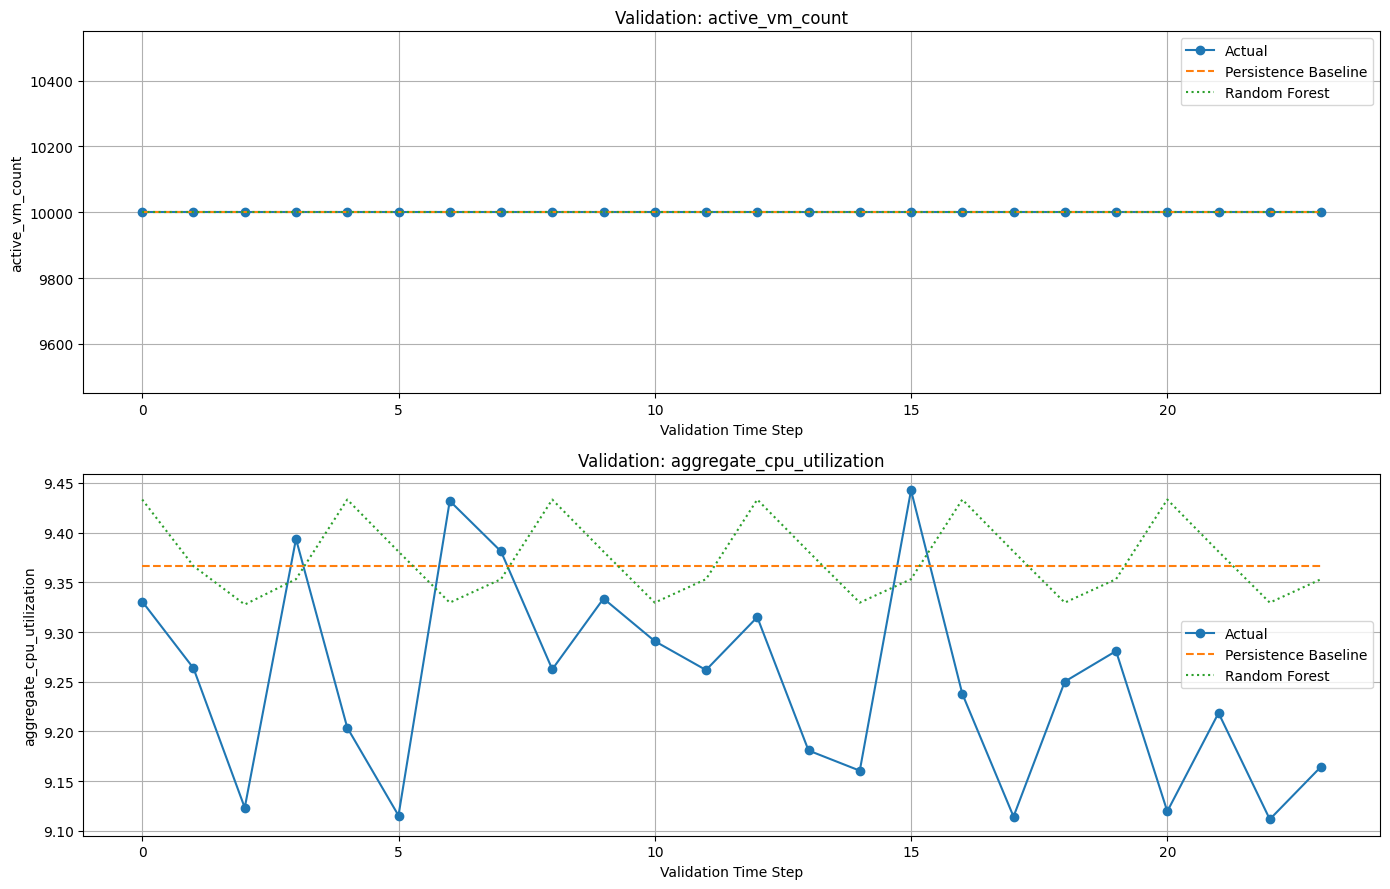

In [96]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

for i, target in enumerate(TARGET_COLS):
    axes[i].plot(
        range(len(y_validation)),
        y_validation[target],
        label="Actual",
        marker="o"
    )

    axes[i].plot(
        range(len(y_validation)),
        baseline_validation_predictions[:, i],
        label="Persistence Baseline",
        linestyle="--"
    )

    axes[i].plot(
        range(len(y_validation)),
        rf_validation_predictions[:, i],
        label="Random Forest",
        linestyle=":"
    )

    axes[i].set_title(f"Validation: {target}")
    axes[i].set_xlabel("Validation Time Step")
    axes[i].set_ylabel(target)
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()

In [97]:
baseline_test_predictions = persistence_baseline(
    history,
    steps=24
)

baseline_test_df = pd.DataFrame(
    baseline_test_predictions,
    columns=TARGET_COLS
)

print(baseline_test_df.head())
print("Total baseline predictions:", len(baseline_test_df))

   active_vm_count  aggregate_cpu_utilization
0          10000.0                   9.164556
1          10000.0                   9.164556
2          10000.0                   9.164556
3          10000.0                   9.164556
4          10000.0                   9.164556
Total baseline predictions: 24


In [98]:
X_full_train = pd.DataFrame(
    x_train,
    columns=FEATURE_COLS
)

Y_full_train = pd.DataFrame(
    y_train,
    columns=TARGET_COLS
)

final_model = MultiOutputRegressor(GradientBoostingRegressor(
        loss='squared_error', learning_rate=0.001,
        n_estimators=300,criterion='squared_error',
        max_depth=3,subsample=0.8,random_state=42)
        )

final_model.fit(
    X_full_train,
    Y_full_train
)

rf_test_predictions = recursive_forecast(
    final_model,
    history,
    steps=24
)

rf_test_df = pd.DataFrame(
    rf_test_predictions,
    columns=TARGET_COLS
)

print(rf_test_df.head())
print("Total Gradient Boosting predictions:", len(rf_test_df))

   active_vm_count  aggregate_cpu_utilization
0          10000.0                   9.363437
1          10000.0                   9.384627
2          10000.0                   9.385729
3          10000.0                   9.398827
4          10000.0                   9.405105
Total Gradient Boosting predictions: 24


In [99]:
actual_test = pd.DataFrame(
    y_test,
    columns=TARGET_COLS
)

test_results = []

test_results.extend(
    calculate_metrics(
        actual_test,
        baseline_test_predictions,
        "Persistence Baseline"
    )
)

test_results.extend(
    calculate_metrics(
        actual_test,
        rf_test_predictions,
        "Gradient Boosting"
    )
)

test_metrics = pd.DataFrame(test_results)

test_metrics.round(4)

,Model,Target,MAE,MSE,RMSE
0,Persistence Baseline,active_vm_count,0.0000,0.0000,0.0000
1,Persistence Baseline,aggregate_cpu_utilization,0.1468,0.0341,0.1848
2,Gradient Boosting,active_vm_count,0.0000,0.0000,0.0000
3,Gradient Boosting,aggregate_cpu_utilization,0.1664,0.0397,0.1992


## Direct Comparing tow models

In [100]:
comparison = test_metrics.pivot(
    index="Target",
    columns="Model",
    values=["MAE", "MSE", "RMSE"]
)

comparison.round(4)

MAE                       \
Model                     Gradient Boosting Persistence Baseline   
Target                                                             
active_vm_count                      0.0000               0.0000   
aggregate_cpu_utilization            0.1664               0.1468   

                                        MSE                       \
Model                     Gradient Boosting Persistence Baseline   
Target                                                             
active_vm_count                      0.0000               0.0000   
aggregate_cpu_utilization            0.0397               0.0341   

                                       RMSE                       
Model                     Gradient Boosting Persistence Baseline  
Target                                                            
active_vm_count                      0.0000               0.0000  
aggregate_cpu_utilization            0.1992               0.1848

In [101]:
improvement_results = []

for target in TARGET_COLS:
    target_results = test_metrics[
        test_metrics["Target"] == target
    ].set_index("Model")

    baseline_mae = target_results.loc[
        "Persistence Baseline", "MAE"
    ]

    model_mae = target_results.loc[
        "Gradient Boosting", "MAE"
    ]

    if baseline_mae != 0:
        improvement = (
            (baseline_mae - model_mae) / baseline_mae
        ) * 100
    else:
        improvement = np.nan

    improvement_results.append({
        "Target": target,
        "Baseline MAE": baseline_mae,
        "Gradient Boosting MAE": model_mae,
        "MAE Improvement (%)": improvement
    })

improvement_df = pd.DataFrame(improvement_results)

improvement_df.round(4)

,Target,Baseline MAE,Gradient Boosting MAE,MAE Improvement (%)
0,active_vm_count,0.0000,0.0000,NaN
1,aggregate_cpu_utilization,0.1468,0.1664,-13.3923


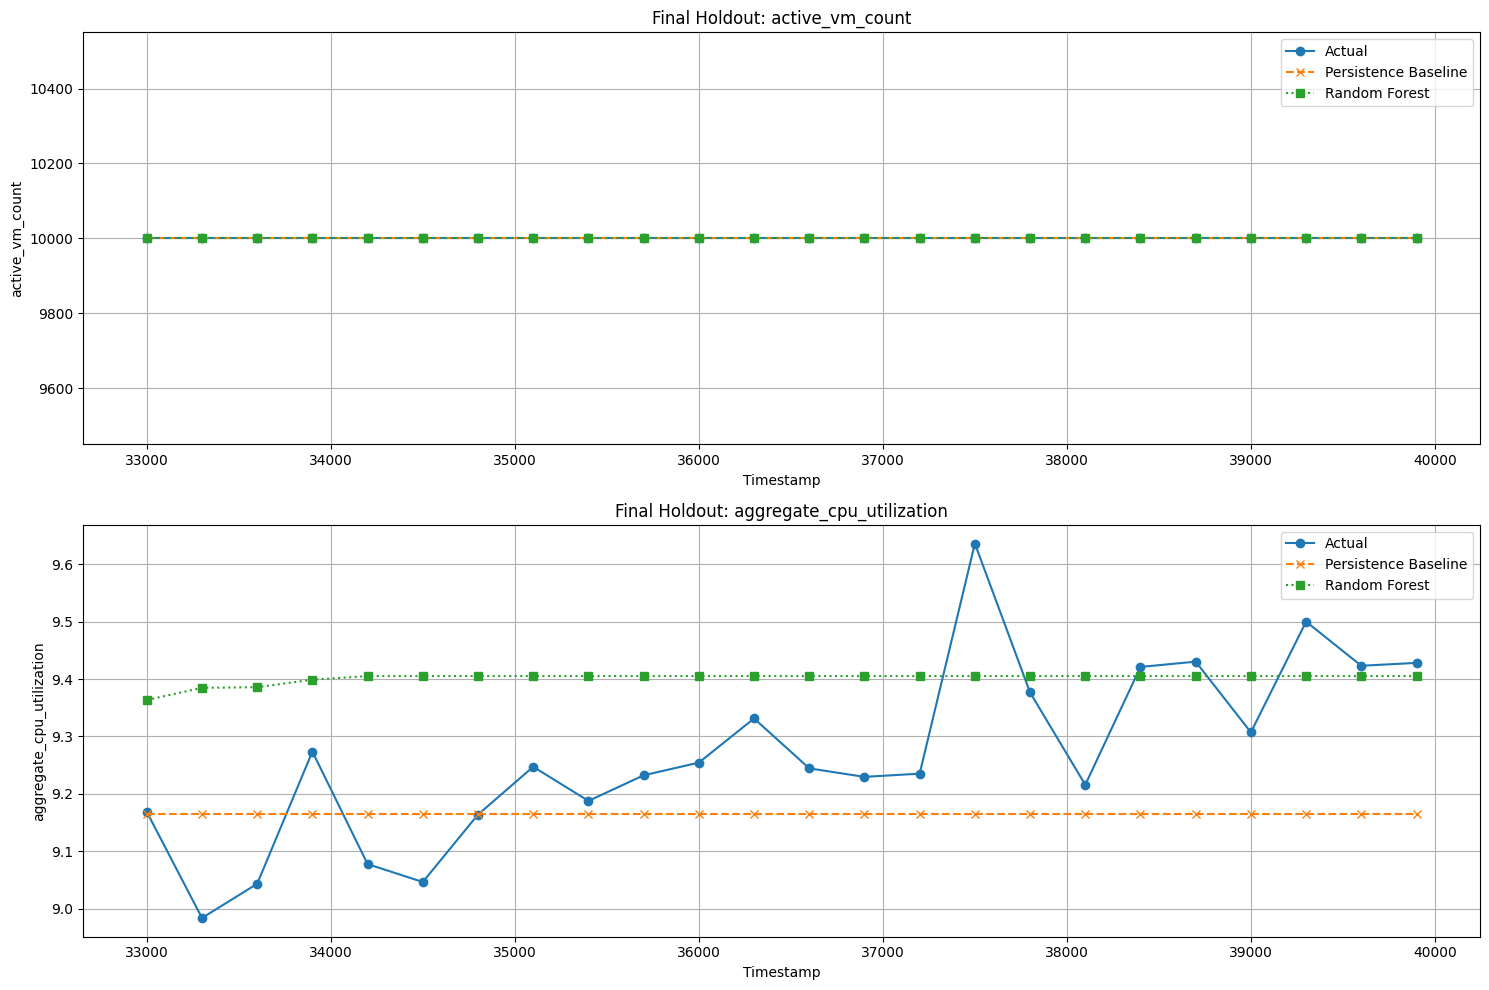

In [102]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

for i, target in enumerate(TARGET_COLS):
    axes[i].plot(
        timestamps_test,
        actual_test[target],
        label="Actual",
        marker="o"
    )

    axes[i].plot(
        timestamps_test,
        baseline_test_predictions[:, i],
        label="Persistence Baseline",
        linestyle="--",
        marker="x"
    )

    axes[i].plot(
        timestamps_test,
        rf_test_predictions[:, i],
        label="Random Forest",
        linestyle=":",
        marker="s"
    )

    axes[i].set_title(f"Final Holdout: {target}")
    axes[i].set_xlabel("Timestamp")
    axes[i].set_ylabel(target)
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()

## Tables Save 

In [103]:
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

test_metrics.to_csv(
    REPORTS_DIR / "baseline_vs_gradient_boosting_metrics.csv",
    index=False
)

improvement_df.to_csv(
    REPORTS_DIR / "baseline_improvement.csv",
    index=False
)

print("Evaluation tables saved successfully in the reports folder.")

Evaluation tables saved successfully in the reports folder.


## Conclusion

The Persistence Baseline provides a simple reference for
evaluating cloud workload forecasts.

We evaluated the baseline and Gradient Boosting using a
time-aware validation experiment and compared their
predictions on the same final 24 observations.

We reported MAE, MSE, and RMSE for both targets:
- active_vm_count
- aggregate_cpu_utilization

We also examined the predictions graphically and evaluated
performance during high-load periods.

The model with the lowest error is not automatically the
best operational choice. Forecast stability, peak-period
performance, and the consequences of under-provisioning
must also be considered.

The results should be interpreted in the context of the
short observation window and the two-hour forecast horizon.